# Flowers 102 Image Classification using ResNet

## 1. Kiểm tra môi tường và dữ liệu

### Import các package cần thiết

In [88]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import os

from pathlib import Path

from collections import Counter
from torchvision.datasets import ImageFolder
from PIL import Image

from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights
import torch.optim as optim
import torch.nn as nn

### Kiểm tra môi trường đã có GPU chưa

In [89]:
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
CUDA available: True
Device: cuda


### Define các dataset directories

In [90]:
DATASET_ROOT = Path(
    "/kaggle/input/datasets/yousefmohamed20/oxford-102-flower-dataset/102 flower/flowers"
)

TRAIN_DIR = DATASET_ROOT / "train"
VALID_DIR = DATASET_ROOT / "valid"
TEST_DIR = DATASET_ROOT / "test"

import json

with open(DATASET_ROOT / "../cat_to_name.json", "r") as f:
    cat_to_name = json.load(f)

print('>>> Đã define các directories:')
print(f"Train data: {TRAIN_DIR}")
print(f"Test data: {TEST_DIR}")
print(f"Val data: {VALID_DIR}")

>>> Đã define các directories:
Train data: /kaggle/input/datasets/yousefmohamed20/oxford-102-flower-dataset/102 flower/flowers/train
Test data: /kaggle/input/datasets/yousefmohamed20/oxford-102-flower-dataset/102 flower/flowers/test
Val data: /kaggle/input/datasets/yousefmohamed20/oxford-102-flower-dataset/102 flower/flowers/valid


### Thống kế số lượng ảnh / lớp của tập train và val

In [91]:
train_raw = ImageFolder(TRAIN_DIR)
valid_raw = ImageFolder(VALID_DIR)

train_counts = Counter(train_raw.targets)
valid_counts = Counter(valid_raw.targets)


summary = pd.DataFrame({
    "Dataset": ["Train", "Validation"],
    "Total images": [
        len(train_raw),
        len(valid_raw)
    ],
    "Min images/class": [
        min(train_counts.values()),
        min(valid_counts.values())
    ],
    "Max images/class": [
        max(train_counts.values()),
        max(valid_counts.values())
    ],
    "Avg images/class": [
        sum(train_counts.values()) / len(train_counts),
        sum(valid_counts.values()) / len(valid_counts)
    ]
})

print(f"Số lượng lớp: {len(train_raw.classes)}")
display(summary.round(2))

Số lượng lớp: 102


,Dataset,Total images,Min images/class,Max images/class,Avg images/class
0,Train,6552,27,206,64.24
1,Validation,818,1,28,8.02


### Minh họa phân phối ảnh trên tập train

Saved: figures/training_images_per_class.png


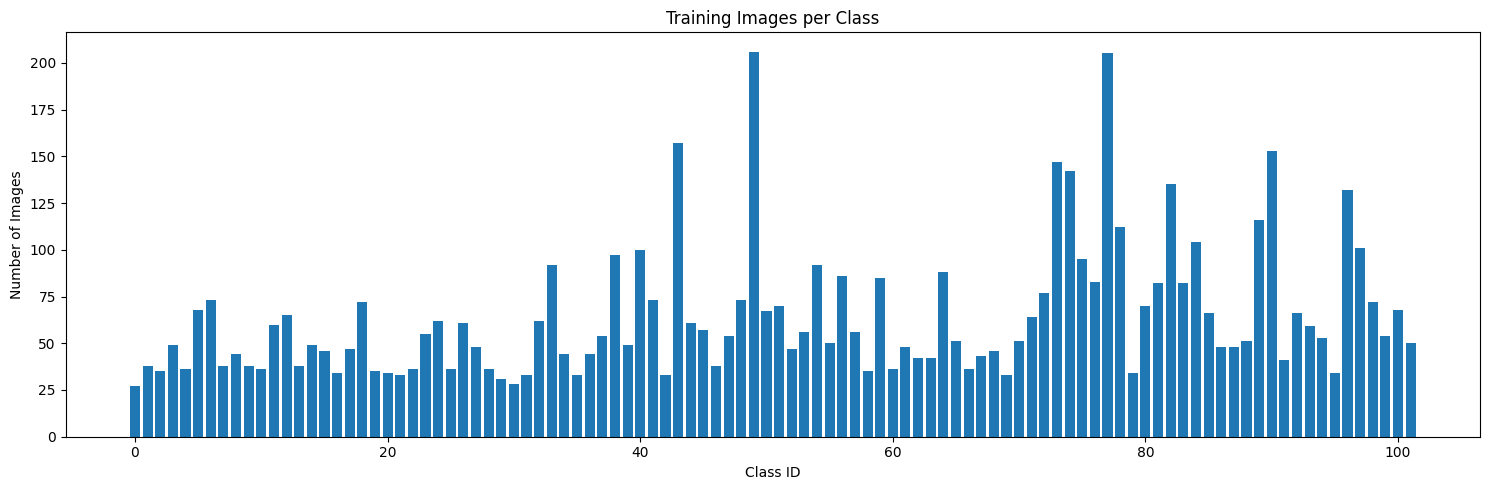

In [92]:
class_ids = range(len(train_counts))
counts = [train_counts[i] for i in class_ids]

plt.figure(figsize=(15, 5))
plt.bar(class_ids, counts)

plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.title("Training Images per Class")

plt.tight_layout()
output_path = Path("figures/training_images_per_class.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=200, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

### Thống kê chất lượng ảnh trên tập train

,Dimension,Min,Max
0,Width,500,1024
1,Height,500,1168


Saved: figures/image_resolution_distribution.png


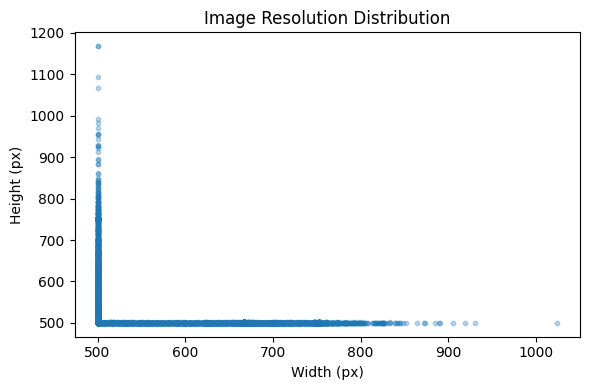

In [93]:
widths = []
heights = []

for image_path, _ in train_raw.samples:
    with Image.open(image_path) as img:
        width, height = img.size
        widths.append(width)
        heights.append(height)

widths = np.array(widths)
heights = np.array(heights)

size_summary = pd.DataFrame({
    "Dimension": ["Width", "Height"],
    "Min": [
        widths.min(),
        heights.min()
    ],
    "Max": [
        widths.max(),
        heights.max()
    ]
})
display(size_summary)

plt.figure(figsize=(6, 4))
plt.scatter(widths, heights, alpha=0.3, s=10)
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.title("Image Resolution Distribution")

plt.tight_layout()
output_path = Path("figures/image_resolution_distribution.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=200, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

### In ra một số sample trên tập train

Saved: figures/sample_flowers.png


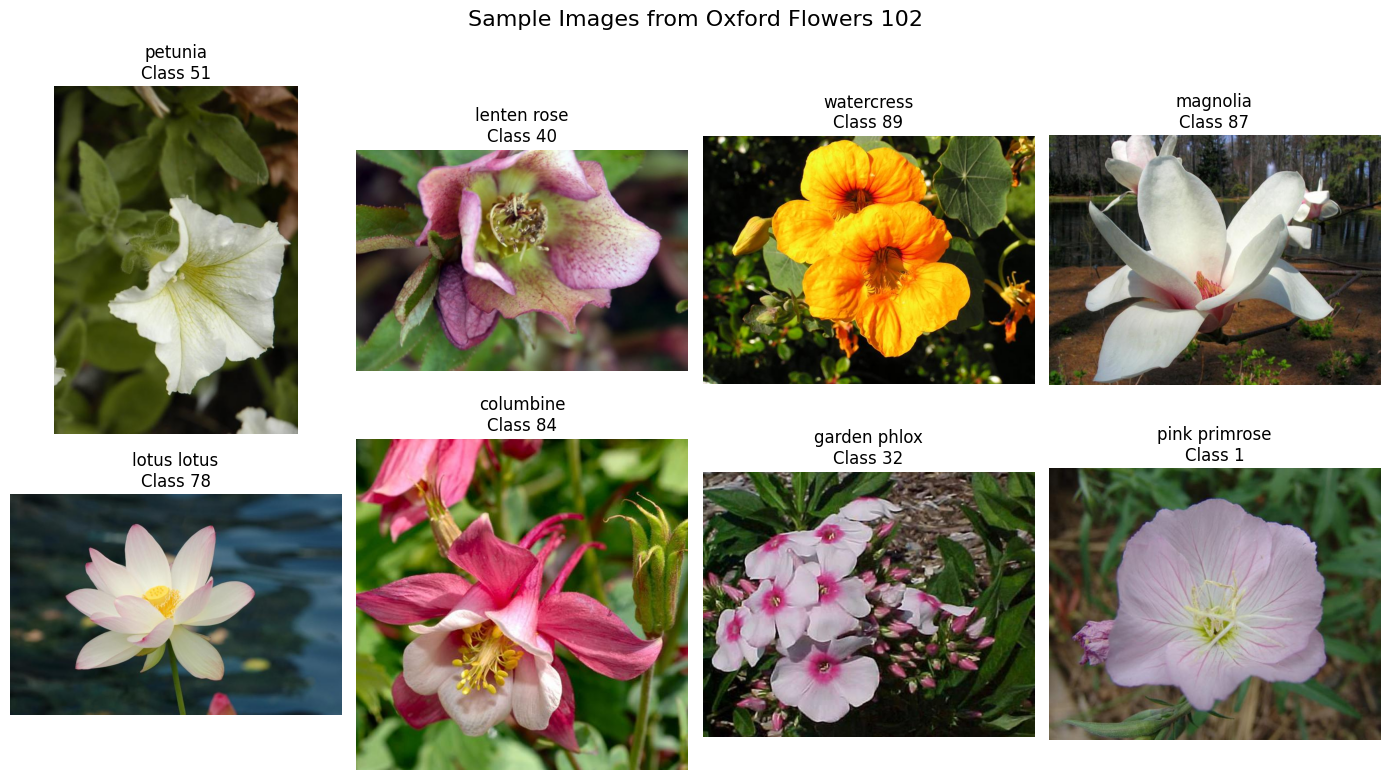

In [94]:
import random

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

indices = random.sample(range(len(train_raw)), 8)

for ax, idx in zip(axes.flat, indices):
    image, label = train_raw[idx]

    class_id = train_raw.classes[label]
    class_name = cat_to_name[class_id]

    ax.imshow(image)
    ax.set_title(f"{class_name}\nClass {class_id}")
    ax.axis("off")

plt.suptitle("Sample Images from Oxford Flowers 102", fontsize=16)
plt.tight_layout()
output_path = Path("figures/sample_flowers.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=200, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

## 2. Image processing và tăng cường dữ liệu

### Cấu hình image processing cho tập train và val + tăng cường dữ liệu trên tập train

In [95]:
transforms = torchvision.transforms
IMG_SIZE = 224 # ResNet sử dụng 224 x 224
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

train_transform_no_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

train_transform_aug = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
])

valid_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
])

### In ra một số sample cho cấu hình augmentation lên ảnh

Saved: figures/augmentation_examples.png


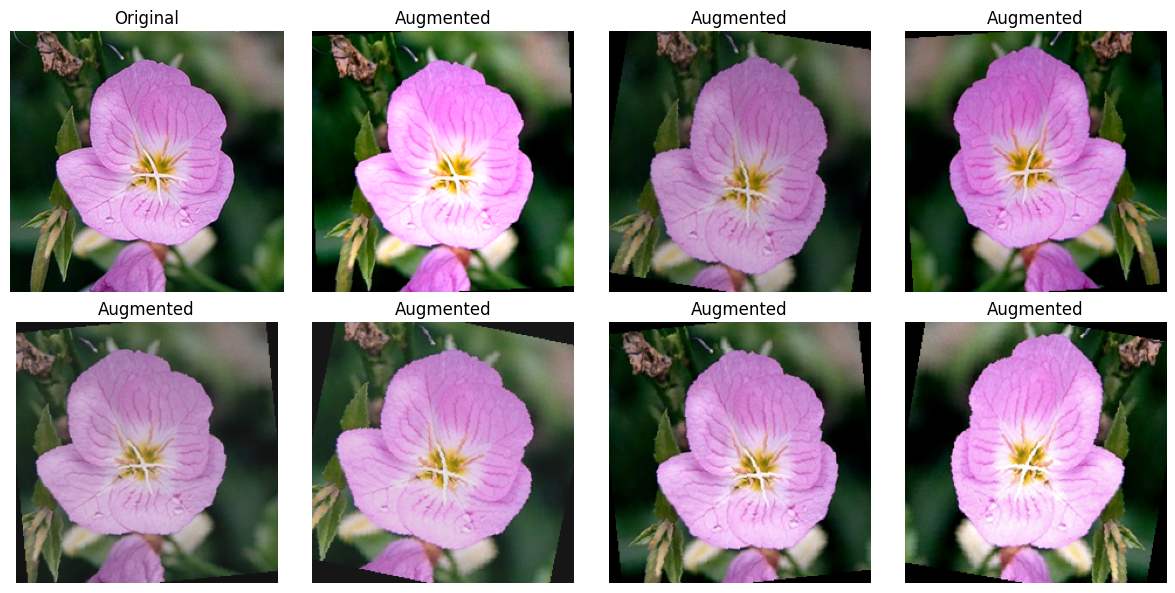

In [96]:
image, label = train_raw[0]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

axes[0, 0].imshow(image)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

for ax in axes.flat[1:]:
    augmented = train_transform_aug(image)

    ax.imshow(augmented.permute(1, 2, 0))
    ax.set_title("Augmented")
    ax.axis("off")

plt.tight_layout()
output_path = Path("figures/augmentation_examples.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=200, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

## 3. Data loader

### Define các loader: train no augmentation, train with augmentation, val, và test loader

In [97]:
# Tạo data train (ko tắng cường) và loader
train_dataset_no_aug = ImageFolder(
    TRAIN_DIR,
    transform=train_transform_no_aug
)

train_loader_no_aug = DataLoader(
    train_dataset_no_aug,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# Tạo data aug và loader
train_dataset_aug = ImageFolder(
    TRAIN_DIR,
    transform=train_transform_aug
)

train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# Tạo data val và loader
valid_dataset = ImageFolder(
    VALID_DIR,
    transform=valid_transform
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Tạo data test và loader để đánh giá cuối cùng
test_dataset = ImageFolder(
    TEST_DIR,
    transform=valid_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


## 4. ResNet-18 setup

### Define hàm khởi tạo model ResNet
Dùng trọng số có sẵn của model

In [98]:
class_number = len(train_raw.classes)

def create_model():
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    
    model.fc = nn.Linear(
        model.fc.in_features,
        class_number
    )

    model = model.to(device)   

    return model

## 5. Train và evaluate

### Define hàm train trong 1 epoch

In [99]:
def epoch_train(model, loss_function, optimizer, loader, device):
    model.train()

    running_loss = 0.0
    running_correct = 0
    total = 0

    # Chạy qua từng batch
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_function(outputs, labels)
        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        running_correct += (predictions == labels).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = running_correct / total

    return epoch_loss, epoch_accuracy

# for images, labels in train_loader_no_aug:
#     print('>>>', labels, images)

### Define hàm evaluate sử dụng model train lên tập val trong quá trình train

In [100]:
def evaluate(model, loss_function, loader, device):
    model.eval()

    running_loss = 0.0
    running_correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = loss_function(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            running_correct += (predictions == labels).sum().item()
            total += labels.size(0)

    loss = running_loss / total
    accuracy = running_correct / total

    return loss, accuracy

### Define hàm train model chung

In [101]:
def train_model(model, train_loader, val_loader, loss_function, optimizer, device, epochs):
    history = {
            "train_loss": [],
            "train_acc": [],
            "val_loss": [],
            "val_acc": []
        }

    for epoch in range(epochs):
        train_loss, train_acc = epoch_train(
            model = model,
            loss_function = loss_function,
            loader = train_loader,
            optimizer = optimizer,
            device = device
        )

        val_loss, val_acc = evaluate(
            model = model,
            loss_function = loss_function,
            loader = val_loader,
            device = device
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"=== Epoch [{epoch + 1}/{epochs}] ===================")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2%}")
        print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2%}")

    return history

### Define các assets cần: loss function, epoch, learning rate, optimizer và train model với tập ko augmented

In [102]:
loss_func = nn.CrossEntropyLoss()

EPOCHS = 10
LEARNING_RATE = 1e-4

model_no_aug = create_model()
optimizer = optim.Adam(
    model_no_aug.parameters(),
    lr=LEARNING_RATE
)
print("Đã setup xong loss function và optimizer!")

history_train_no_aug = train_model(
    model=model_no_aug,
    train_loader=train_loader_no_aug,
    val_loader=valid_loader,
    loss_function=loss_func,
    optimizer=optimizer,
    epochs=EPOCHS,
    device=device
)


Đã setup xong loss function và optimizer!
=== Epoch [1/10] ===================
Train Loss: 1.9738 | Train Acc: 65.22%
Val Loss: 1.8339 | Val Acc: 68.22%
=== Epoch [2/10] ===================
Train Loss: 0.3453 | Train Acc: 97.21%
Val Loss: 1.3147 | Val Acc: 71.39%
=== Epoch [3/10] ===================
Train Loss: 0.0911 | Train Acc: 99.69%
Val Loss: 1.1121 | Val Acc: 76.16%
=== Epoch [4/10] ===================
Train Loss: 0.0395 | Train Acc: 99.97%
Val Loss: 1.0419 | Val Acc: 76.28%
=== Epoch [5/10] ===================
Train Loss: 0.0211 | Train Acc: 100.00%
Val Loss: 0.9206 | Val Acc: 78.85%
=== Epoch [6/10] ===================
Train Loss: 0.0134 | Train Acc: 100.00%
Val Loss: 0.9198 | Val Acc: 79.58%
=== Epoch [7/10] ===================
Train Loss: 0.0093 | Train Acc: 100.00%
Val Loss: 0.8430 | Val Acc: 80.44%
=== Epoch [8/10] ===================
Train Loss: 0.0076 | Train Acc: 100.00%
Val Loss: 0.8658 | Val Acc: 78.97%
=== Epoch [9/10] ===================
Train Loss: 0.0059 | Train Ac

### Làm tương tự với model với data augmented

In [103]:
model_aug = create_model()

loss_func_aug = nn.CrossEntropyLoss()

optimizer_aug = optim.Adam(
    model_aug.parameters(),
    lr=LEARNING_RATE
)

history_train_aug = train_model(
    model=model_aug,
    train_loader=train_loader_aug,
    val_loader=valid_loader,
    loss_function=loss_func_aug,
    optimizer=optimizer_aug,
    device=device,
    epochs=EPOCHS
)

=== Epoch [1/10] ===================
Train Loss: 2.1607 | Train Acc: 59.07%
Val Loss: 0.8165 | Val Acc: 88.88%
=== Epoch [2/10] ===================
Train Loss: 0.5257 | Train Acc: 93.44%
Val Loss: 0.3659 | Val Acc: 94.50%
=== Epoch [3/10] ===================
Train Loss: 0.2222 | Train Acc: 97.51%
Val Loss: 0.2435 | Val Acc: 96.45%
=== Epoch [4/10] ===================
Train Loss: 0.1127 | Train Acc: 99.11%
Val Loss: 0.1827 | Val Acc: 96.58%
=== Epoch [5/10] ===================
Train Loss: 0.0635 | Train Acc: 99.65%
Val Loss: 0.1737 | Val Acc: 97.07%
=== Epoch [6/10] ===================
Train Loss: 0.0529 | Train Acc: 99.39%
Val Loss: 0.2212 | Val Acc: 94.50%
=== Epoch [7/10] ===================
Train Loss: 0.0367 | Train Acc: 99.65%
Val Loss: 0.1633 | Val Acc: 96.09%
=== Epoch [8/10] ===================
Train Loss: 0.0265 | Train Acc: 99.85%
Val Loss: 0.1428 | Val Acc: 96.82%
=== Epoch [9/10] ===================
Train Loss: 0.0221 | Train Acc: 99.86%
Val Loss: 0.1594 | Val Acc: 96.33%
=

### Vẽ hình so sánh thay đổi train loss và val loss của 2 model

Saved: figures/training_validation_loss.png


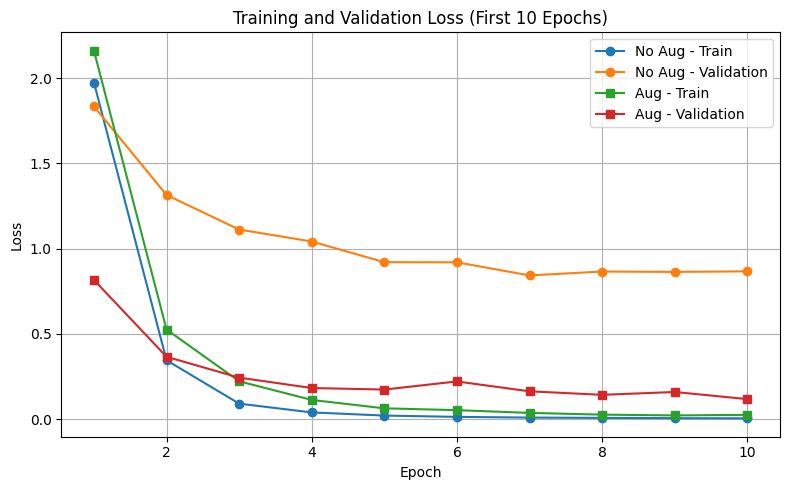

In [104]:
import matplotlib.pyplot as plt

num_epochs = 10
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_train_no_aug["train_loss"][:num_epochs],
    marker="o",
    label="No Aug - Train",
)
plt.plot(
    epochs,
    history_train_no_aug["val_loss"][:num_epochs],
    marker="o",
    label="No Aug - Validation",
)

plt.plot(
    epochs,
    history_train_aug["train_loss"][:num_epochs],
    marker="s",
    label="Aug - Train",
)
plt.plot(
    epochs,
    history_train_aug["val_loss"][:num_epochs],
    marker="s",
    label="Aug - Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss (First 10 Epochs)")
plt.legend()
plt.grid(True)
plt.tight_layout()
output_path = Path("figures/training_validation_loss.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=200, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

### Vẽ hình so sánh thay đổi accuracy của train dataset và val dataset của 2 model

Saved: figures/training_validation_accuracy.png


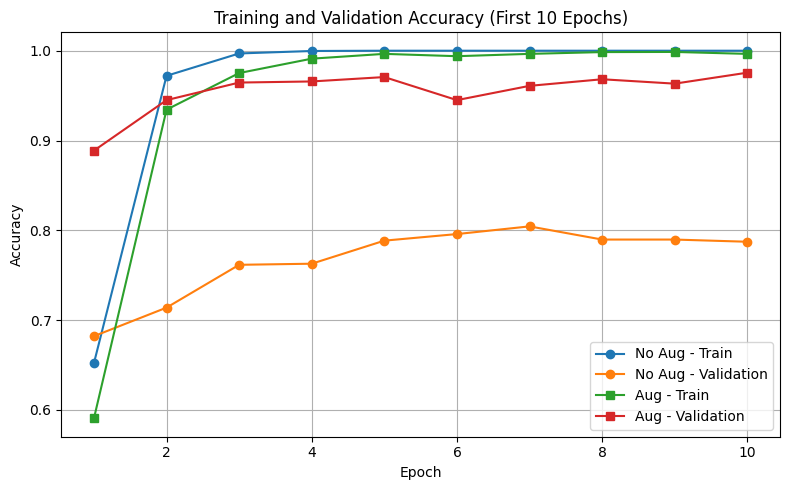

In [105]:
import matplotlib.pyplot as plt

num_epochs = 10
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_train_no_aug["train_acc"][:num_epochs],
    marker="o",
    label="No Aug - Train",
)
plt.plot(
    epochs,
    history_train_no_aug["val_acc"][:num_epochs],
    marker="o",
    label="No Aug - Validation",
)

plt.plot(
    epochs,
    history_train_aug["train_acc"][:num_epochs],
    marker="s",
    label="Aug - Train",
)
plt.plot(
    epochs,
    history_train_aug["val_acc"][:num_epochs],
    marker="s",
    label="Aug - Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy (First 10 Epochs)")
plt.legend()
plt.grid(True)
plt.tight_layout()
output_path = Path("figures/training_validation_accuracy.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=200, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

### Confusion matrix của augmented-model lên tập test

Saved: figures/confusion_matrix_augmented_model.png


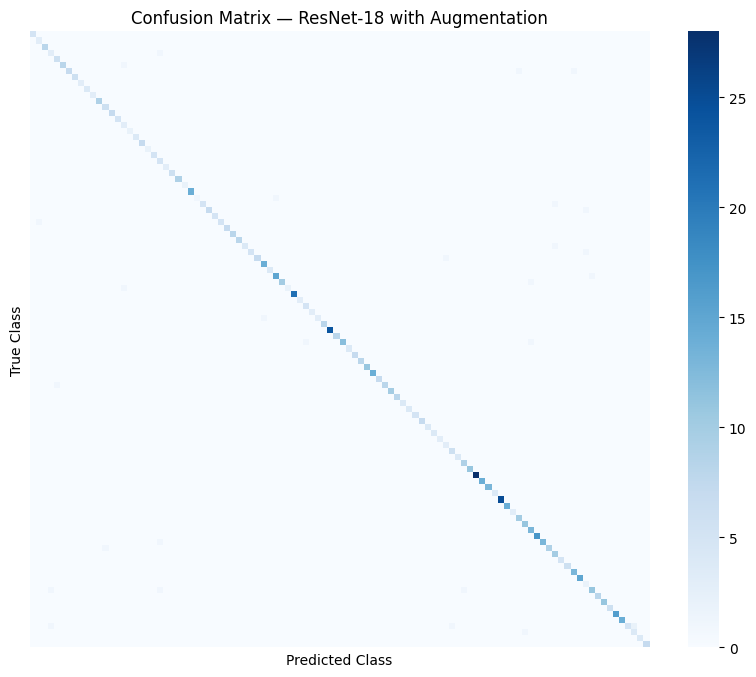

In [106]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

model_aug.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_aug(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=False,
    yticklabels=False
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix — ResNet-18 with Augmentation")
output_path = Path("figures/confusion_matrix_augmented_model.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=200, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

### In ra randome kết quả dự đoán của augmented model trên tập test

Saved: figures/random_test_predictions.png


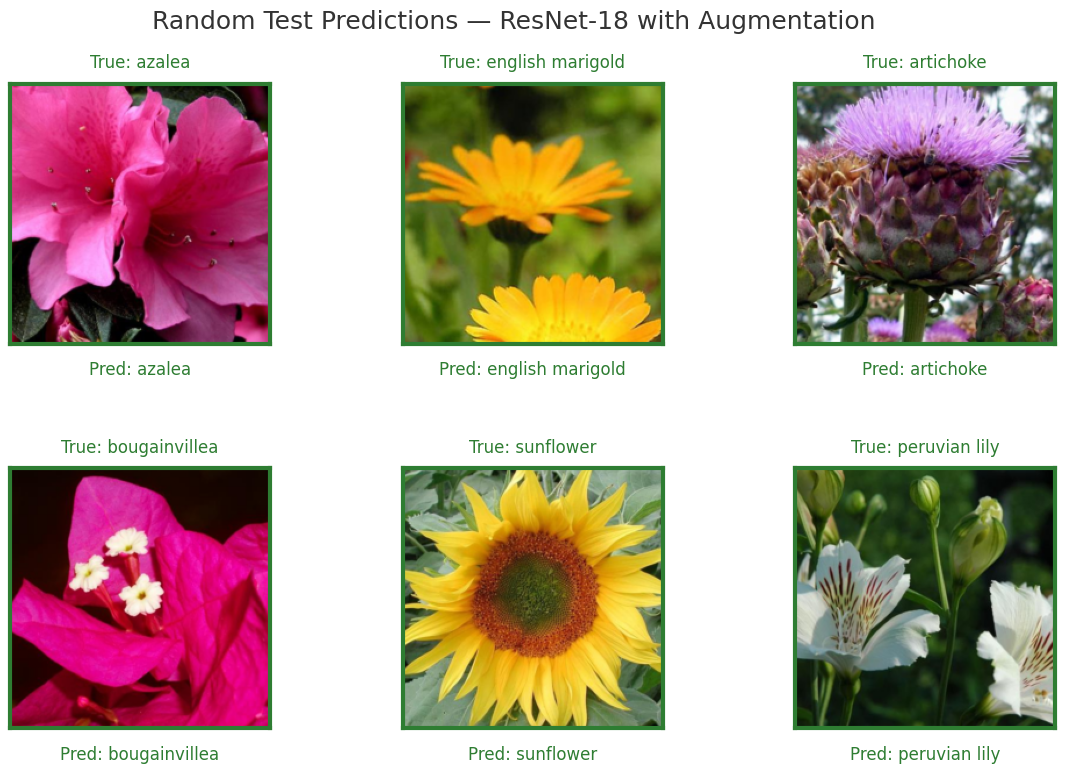

In [107]:
import random
import textwrap
import math

NUM_SAMPLES = 6
GREEN, RED = "#2e7d32", "#c62828"

def wrap(name, width=24):
    return "\n".join(textwrap.wrap(name, width))

def collect_predictions(model, loader, device):
    model.eval()
    all_labels = []
    all_predictions = []
    total_loss = 0.0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels_device = labels.to(device)
            outputs = model(images)
            loss = loss_func(outputs, labels_device)

            total_loss += loss.item() * labels.size(0)
            total += labels.size(0)
            all_labels.extend(labels.numpy())
            all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())

    return all_labels, all_predictions, total_loss / total

all_labels_aug, all_predictions_aug, loss_aug = collect_predictions(
    model_aug, test_loader, device
)
num_samples = min(NUM_SAMPLES, len(test_dataset))
sample_indices = random.sample(range(len(test_dataset)), num_samples)
samples = [test_dataset[i] for i in sample_indices]
predictions = [all_predictions_aug[i] for i in sample_indices]

num_cols = min(3, num_samples)
num_rows = math.ceil(num_samples / num_cols)
fig, axes = plt.subplots(
    num_rows, num_cols, figsize=(5 * num_cols, 6.2 * num_rows),
    squeeze=False, constrained_layout=False
)
fig.patch.set_facecolor("white")
fig.suptitle("Random Test Predictions — ResNet-18 with Augmentation",
             fontsize=18, color="#333333", y=0.98)

for ax, (image, label), prediction in zip(axes.flat, samples, predictions):
    true_name = cat_to_name.get(
        str(test_dataset.classes[label]), test_dataset.classes[label]
    )
    pred_name = cat_to_name.get(
        str(test_dataset.classes[prediction]), test_dataset.classes[prediction]
    )
    correct = label == prediction
    color = GREEN if correct else RED

    ax.imshow(image.clamp(0, 1).permute(1, 2, 0))
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(3)
    ax.set_title(f"True: {wrap(true_name)}", fontsize=12, color=GREEN, pad=12)
    ax.set_xlabel(f"Pred: {wrap(pred_name)}", fontsize=12, color=color, labelpad=12)

for ax in axes.flat[num_samples:]:
    ax.set_visible(False)

fig.subplots_adjust(top=0.92, bottom=0.4, hspace=0.48, wspace=0.04)
OUTPUT_IMAGE = Path("figures/random_test_predictions.png")
OUTPUT_IMAGE.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_IMAGE, dpi=200, bbox_inches="tight")
print(f"Saved: {OUTPUT_IMAGE}")
plt.show()

### Thống kế lại kết quả metrices của augmented model lên tập test

In [108]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def calculate_metrics(labels, predictions, loss):
    return {
        "Loss": loss,
        "Accuracy": accuracy_score(labels, predictions),
        "Precision (macro)": precision_score(labels, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(labels, predictions, average="macro", zero_division=0),
        "F1 (macro)": f1_score(labels, predictions, average="macro", zero_division=0),
        "Precision (weighted)": precision_score(labels, predictions, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(labels, predictions, average="weighted", zero_division=0),
        "F1 (weighted)": f1_score(labels, predictions, average="weighted", zero_division=0),
    }

comparison = pd.DataFrame(
    [
        calculate_metrics(
            *collect_predictions(model_no_aug, test_loader, device)
        ),
        calculate_metrics(all_labels_aug, all_predictions_aug, loss_aug),
    ],
    index=["No Augmentation", "With Augmentation"]
)

display(comparison.style.format({
    "Loss": "{:.4f}",
    "Accuracy": "{:.2%}",
    "Precision (macro)": "{:.2%}",
    "Recall (macro)": "{:.2%}",
    "F1 (macro)": "{:.2%}",
    "Precision (weighted)": "{:.2%}",
    "Recall (weighted)": "{:.2%}",
    "F1 (weighted)": "{:.2%}",
}))

,Loss,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
No Augmentation,1.0385,73.50%,84.20%,71.80%,72.79%,85.54%,73.50%,74.26%
With Augmentation,0.1444,96.58%,96.12%,96.03%,95.53%,97.26%,96.58%,96.60%
